In [1]:
import pandas as pd

df = pd.read_csv('Dataset_cleaned.csv', parse_dates=['date_added'])

In [2]:
print(df.shape)
df.info()

(8787, 12)
<class 'pandas.DataFrame'>
RangeIndex: 8787 entries, 0 to 8786
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   show_id         8787 non-null   str           
 1   type            8787 non-null   str           
 2   title           8787 non-null   str           
 3   director        8787 non-null   str           
 4   country         8787 non-null   str           
 5   date_added      8787 non-null   datetime64[us]
 6   release_year    8787 non-null   int64         
 7   rating          8787 non-null   str           
 8   duration        8787 non-null   str           
 9   listed_in       8787 non-null   str           
 10  duration_value  8787 non-null   int64         
 11  duration_unit   8787 non-null   str           
dtypes: datetime64[us](1), int64(2), str(9)
memory usage: 823.9 KB


In [3]:
content_counts = df['type'].value_counts()
print(content_counts)

type
Movie      6124
TV Show    2663
Name: count, dtype: int64


In [4]:
total = len(df)
movie_pct = (content_counts['Movie'] / total * 100).round(1)
tv_pct = (content_counts['TV Show'] / total * 100).round(1)

print(f"Movies: {content_counts['Movie']} ({movie_pct}%)")
print(f"TV Shows: {content_counts['TV Show']} ({tv_pct}%)")

Movies: 6124 (69.7%)
TV Shows: 2663 (30.3%)


In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

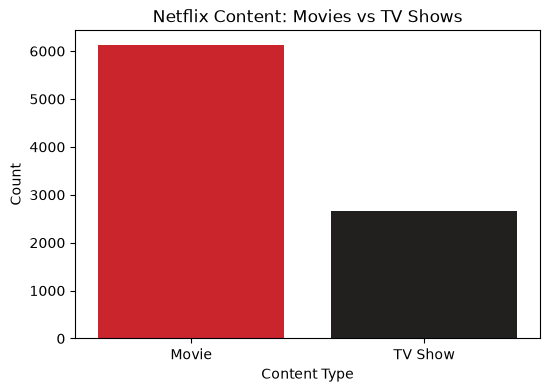

In [6]:
plt.figure(figsize=(6, 4))
sns.barplot(x=content_counts.index, y=content_counts.values, hue=content_counts.index, palette=['#E50914', '#221f1f'], legend=False)
plt.title('Netflix Content: Movies vs TV Shows')
plt.xlabel('Content Type')
plt.ylabel('Count')
plt.show()

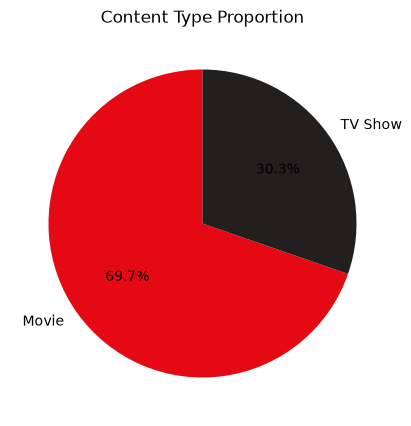

In [7]:
plt.figure(figsize=(5, 5))
plt.pie(content_counts.values, labels=content_counts.index, autopct='%1.1f%%',
        colors=['#E50914', '#221f1f'], startangle=90)
plt.title('Content Type Proportion')
plt.show()

In [8]:
yearly_counts = df.groupby(['release_year', 'type']).size().unstack(fill_value=0)
print(yearly_counts.tail(10))

type          Movie  TV Show
release_year                
2012            173       63
2013            225       61
2014            264       88
2015            396      159
2016            658      243
2017            765      265
2018            766      378
2019            632      397
2020            517      436
2021            277      315


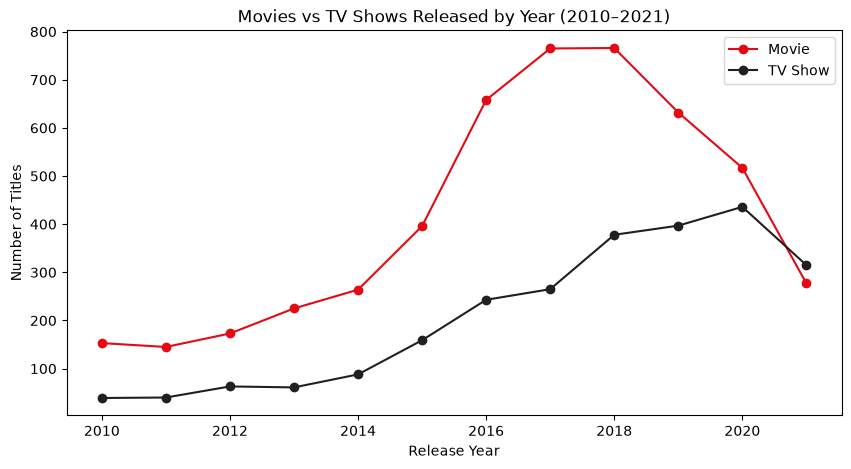

In [9]:
yearly_counts_recent = yearly_counts.loc[2010:2021]

plt.figure(figsize=(10, 5))
plt.plot(yearly_counts_recent.index, yearly_counts_recent['Movie'], label='Movie', color='#E50914', marker='o')
plt.plot(yearly_counts_recent.index, yearly_counts_recent['TV Show'], label='TV Show', color='#221f1f', marker='o')
plt.title('Movies vs TV Shows Released by Year (2010–2021)')
plt.xlabel('Release Year')
plt.ylabel('Number of Titles')
plt.legend()
plt.show()

## Task 2: Content Type Analysis - Summary

### Objective
Analyze the distribution of Movies and TV Shows in the Netflix catalog.

### Key Findings
1. **Overall split:** The catalog is 69.7% Movies (6,124 titles) and 30.3% TV Shows (2,663 titles).
2. **Trend over time:** Both content types grew steadily until around 2017-2018. After that, Movie releases declined (766 in 2018 to 277 in 2021) while TV Show releases kept growing (378 to 436 in 2020), narrowing the gap considerably.
3. **Shifting ratio:** In 2012, Movies outnumbered TV Shows roughly 2.7 to 1. By 2021, TV Shows slightly outnumbered Movies (315 vs 277).
4. **Note on 2021:** The dataset's `date_added` values end in September 2021, so 2021 figures are likely incomplete and shouldn't be read as a full-year decline.

### Business Insight
While Movies still make up the majority of Netflix's overall catalog, the platform's more recent content additions have shifted notably toward TV Shows, suggesting a strategic emphasis on series over films in later years.